# Tổng quan đề tài

Mở từ thư mục dự án với kernel của môi trường dự án. Các ô đọc config, bảng và hình đã công bố.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "reports/stage5_inputs.json").is_file())
sys.path.insert(0, str(root))
from src.wrmsse_stage5 import STAGE2, STAGE3, STAGE4, SELECTED, TABLES, csv, read, check_gates
check_gates()

def table(name):
    return csv(TABLES / (name + ".csv"))

def figure(number):
    path, = (root / "reports/figures").glob(f"{number:02d}_*.png")
    display(Image(filename=str(path), width=950))


Mục tiêu là dự báo lượng bán M5 trong 28 ngày bằng Random Forest Regression và so sánh với Seasonal Naive chu kỳ 7. Thước đo chính là WRMSSE đầy đủ 12 cấp. Thứ tự nghiên cứu ở sơ đồ dưới đây.

,window,first_day,last_day,days
0,Train,1,1885,1885
1,Validation,1886,1913,28
2,Test,1914,1941,28


,thứ_tự,bước,kết_quả
0,1,Tuning ban đầu,RF-04
1,2,Ablation đặc trưng,RF-v1
2,3,Tuning nâng cao,RF-15
3,4,Tối ưu đặc trưng,FE-04
4,5,Fit cuối trên mẫu,609.185 dòng
5,6,Test sau khóa dự báo,WRMSSE M5 · 12 cấp


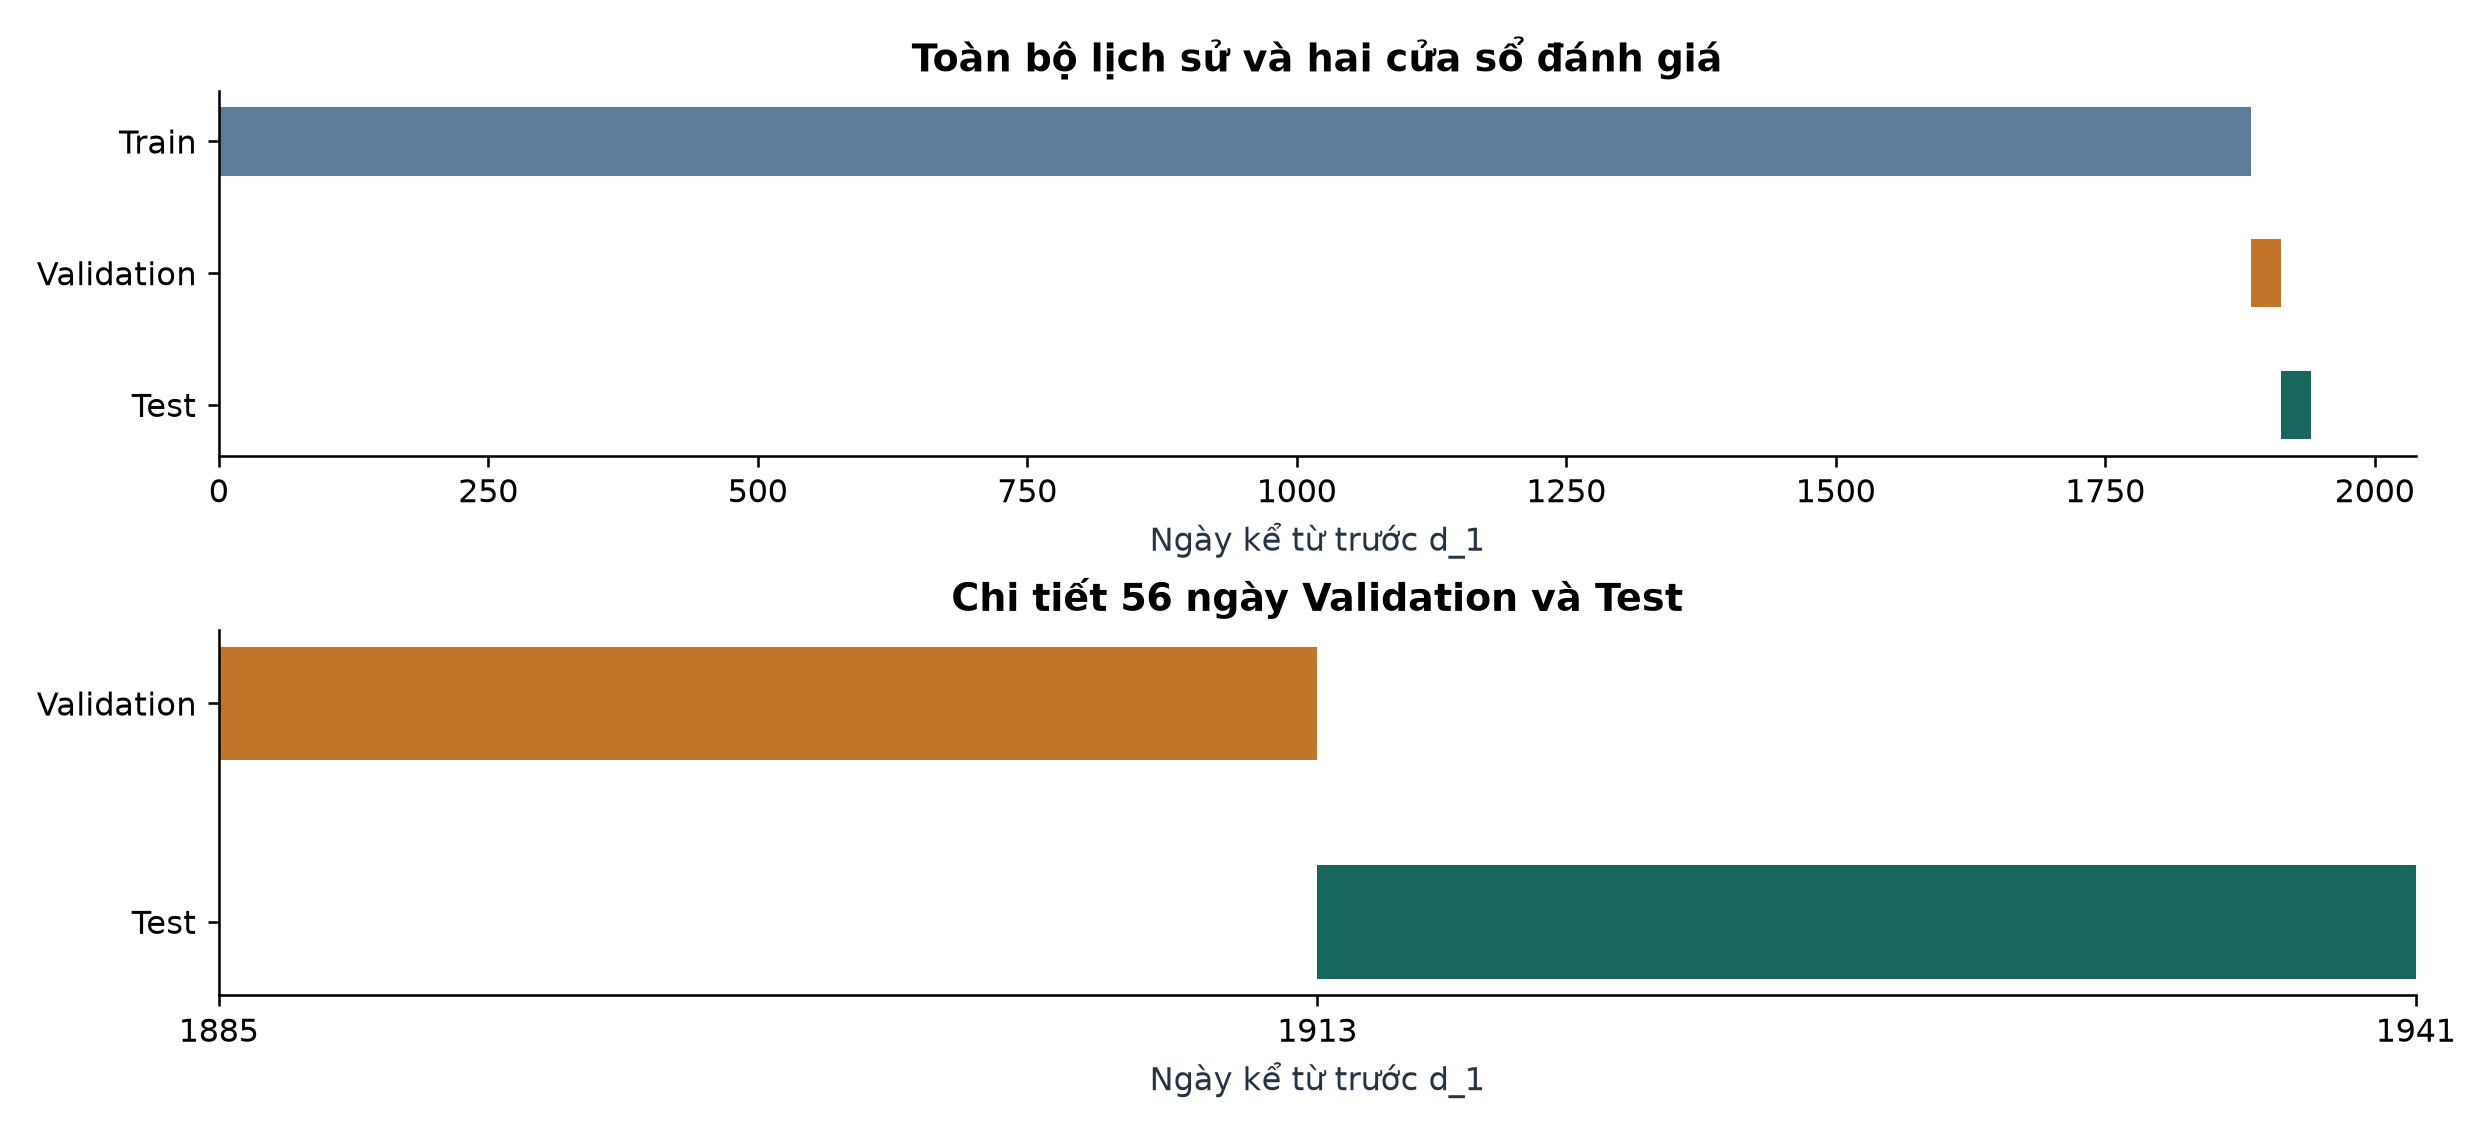

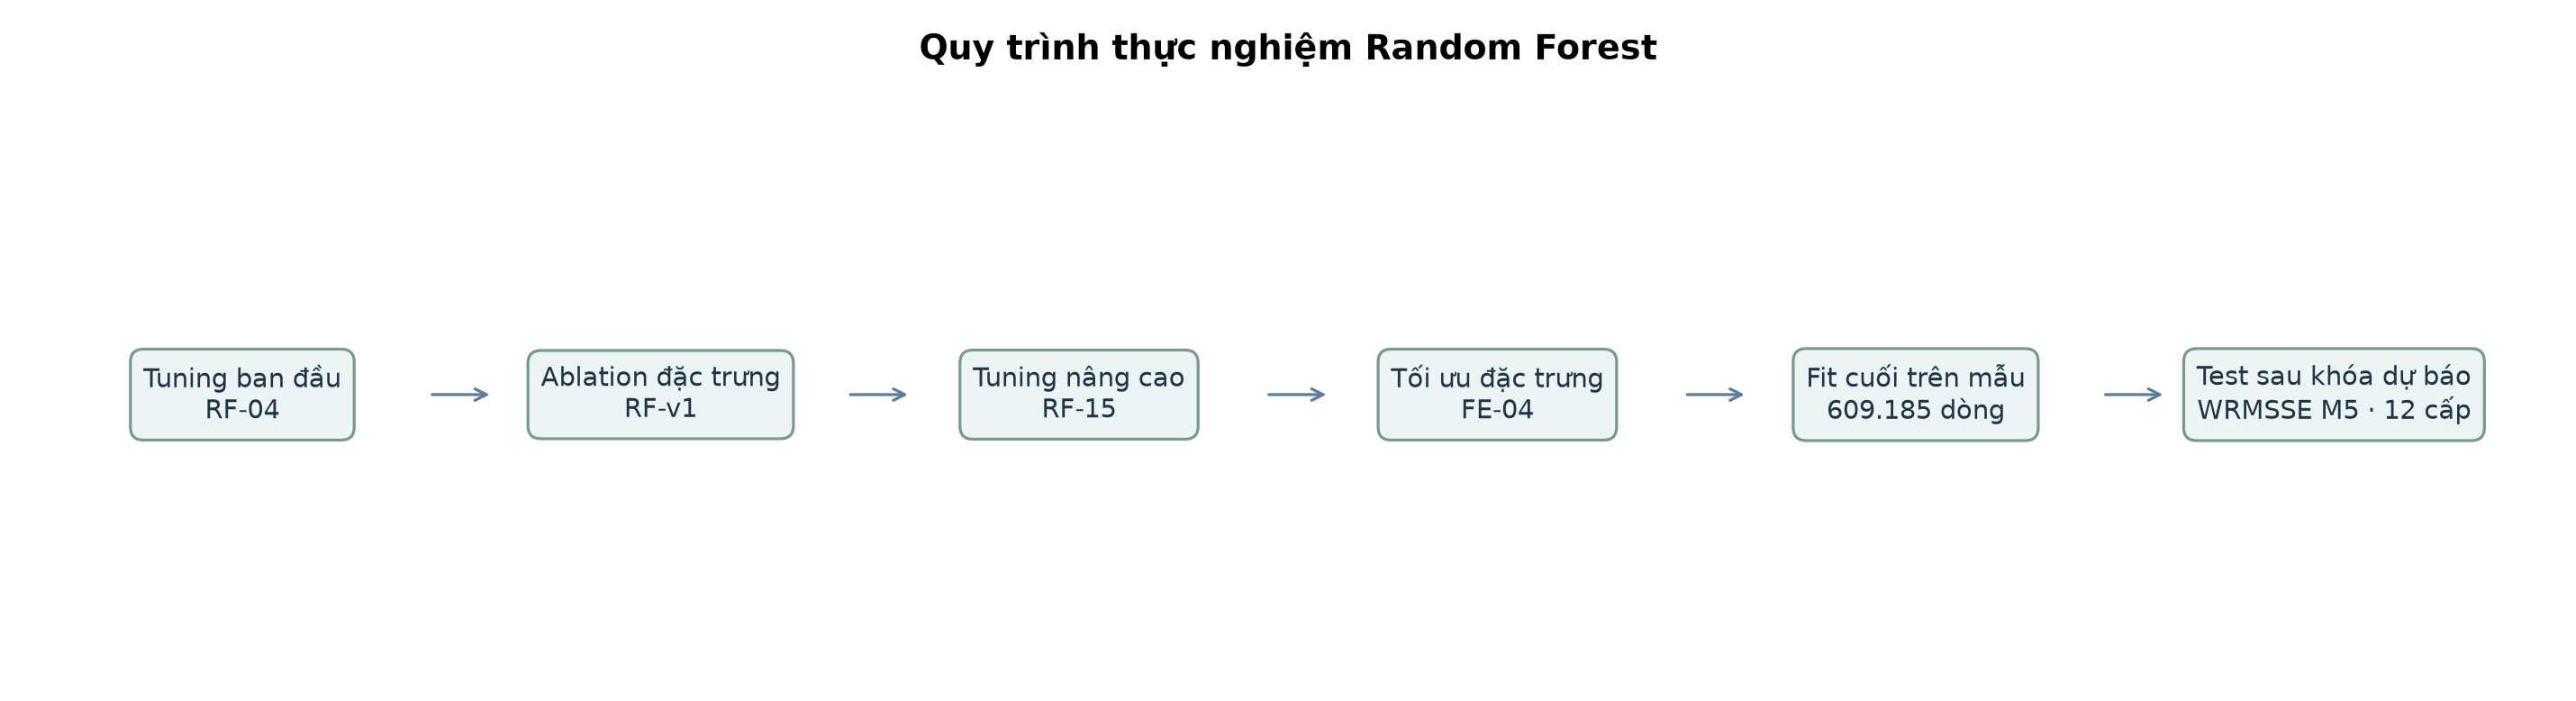

In [2]:
display(table("split_timeline"))
display(table("experiment_workflow"))
figure(1)
figure(2)

Mỗi notebook mặc định đọc artifact của dự án. Chọn kernel Python của môi trường dự án và dùng Run All. Cấu hình, số liệu và cách xem kết quả có trong [README](../README.md).

In [3]:
display(table("validation_test"))
display(read(STAGE4 / "manifest_completed.json")["status"])

,window,random_forest,seasonal_naive,target_days,scale_days,weight_days
0,Validation,0.623931,0.922781,d_1886–d_1913,d_1–d_1885,d_1858–d_1885
1,Test,0.703912,0.869701,d_1914–d_1941,d_1–d_1913,d_1886–d_1913


'completed'